# Do mice use the visual stimulus? Slide figures

Presentation versions of the figures in `vision_search_strategy.ipynb`, which stays the reference (the methods, the tables and the full summary are there). Here:

- Trial types are labelled by flip state and where the stimulus is: **Flip 0** puts the target and the stimulus at the low-y end, **Flip 1** at the high-y end, **Flip 2** has no stimulus.
- The analysis is the same, so every number matches the original notebook. The stimulus-vs-matched comparisons are shown in plain units (% change in path length, percentage points) rather than log2 ratios.
- Each figure is sized for a 16:9 slide at two thirds of its height and saved to `output/slides_vision_search/` as PNG.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src import config as cfg
from src.trials import load_trials          # run `python -m src.trials vision` to rebuild output/trials_vision.csv
from src.stats import stratified_diff, per_mouse, summarize
from src.style import INK, MUTED, GRID, PAPER, SLIDE, use_style

pd.set_option('display.width', 200, 'display.precision', 3)
PAD = 1.25                                  # scales every gap between panels and every margin around them
FIG = (SLIDE[0], SLIDE[1] * 2 / 3)          # full slide width, two thirds of its height
use_style(slides=True)
SLIDES_DIR = cfg.OUT_DIR / 'slides_vision_search'
SLIDES_DIR.mkdir(exist_ok=True)

FLIP_COLOR = {0: '#2a78d6', 1: '#eb6834', 2: '#8a8985'}
FLIP_CUE = {0: 'stimulus low', 1: 'stimulus high', 2: 'no stimulus'}
FLIP_LABEL = {f: f'Flip {f} ({cue})' for f, cue in FLIP_CUE.items()}
LINE = '#2a78d6'

t = load_trials('vision')                    # vision (v) sessions only; t.cue = flip 0 or 1
MICE = sorted(t.mouse.unique())
MOUSE_COLOR = dict(zip(MICE, plt.cm.Set1.colors))
MOUSE_X = dict(zip(MICE, np.linspace(-0.12, 0.12, len(MICE))))   # each mouse's horizontal offset in a dot column

def padded(top, bottom, left, right):
    """Figure-fraction margins, each widened by PAD."""
    return dict(top=1 - (1 - top) * PAD, bottom=bottom * PAD, left=left * PAD, right=1 - (1 - right) * PAD)

def finish(fig, title, name, key=None):
    """Title and footer, both starting at the left edge of the leftmost panel; then save and show."""
    left = min(ax.get_position().x0 for ax in fig.axes)
    fig.suptitle(title, x=left, y=0.98, ha='left', va='top', fontsize=24, fontweight='bold')
    if key:
        fig.text(left, 0.015, key, ha='left', va='bottom', fontsize=13, color=MUTED)
    fig.savefig(SLIDES_DIR / f'{name}.png')
    plt.show()

def mouse_legend(fig, x, y=0.5, loc='center left'):
    """One legend entry per mouse (original IDs), at figure position (x, y)."""
    handles = [plt.Line2D([], [], ls='', marker='o', ms=10, color=MOUSE_COLOR[m], mec=PAPER) for m in MICE]
    fig.legend(handles, MICE, title='Mouse', loc=loc, bbox_to_anchor=(x, y), fontsize=13, title_fontsize=13,
               handletextpad=0.2, labelspacing=0.35)

def tidy(ax):
    ax.yaxis.grid(True, color=GRID); ax.set_axisbelow(True)

## 1. Position at trial start

The negative control: the mouse has no information yet, so where it is when the trial starts must not depend on the trial type. Next to it, the two habits the later comparisons are built to rule out.

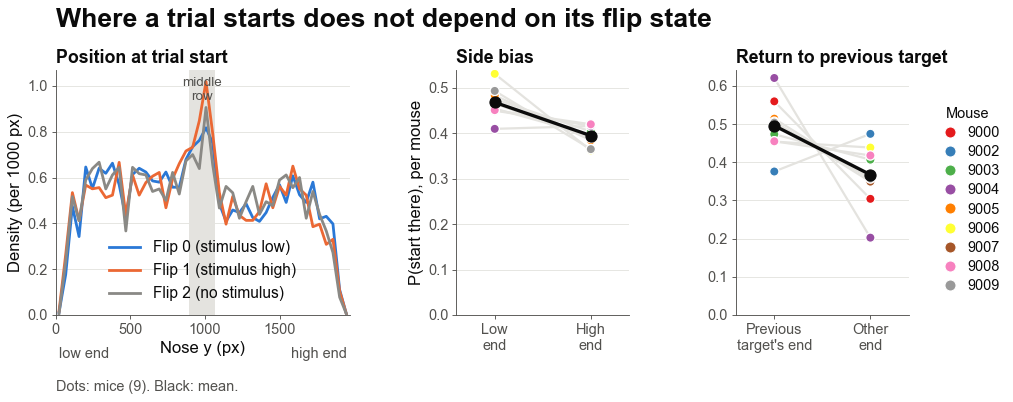

In [2]:
def paired_dots(ax, a, b, labels, title, ylabel):
    for m in a.index:
        ax.plot([0, 1], [a[m], b[m]], color=GRID, lw=2, zorder=1)
    for x, v in ((0, a), (1, b)):
        ax.scatter(np.full(len(v), x), v, s=70, color=[MOUSE_COLOR[m] for m in v.index], zorder=2, edgecolor=PAPER, lw=1.2)
    ax.plot([0, 1], [a.mean(), b.mean()], color=INK, lw=3, marker='o', ms=10, zorder=3)
    ax.set(xticks=[0, 1], xlim=(-0.4, 1.4), ylim=(0, None), ylabel=ylabel)
    ax.set_xticklabels(labels)
    ax.set_title(title, fontsize=16)
    tidy(ax)

fig, axes = plt.subplots(1, 3, figsize=FIG, gridspec_kw={'width_ratios': [1.7, 1, 1], 'wspace': 0.4 * PAD,
                                                         **padded(top=0.86, bottom=0.17, left=0.07, right=0.91)})
ax = axes[0]
bins = np.linspace(0, cfg.FRAME_H, 45)
for flip in (0, 1, 2):
    density, _ = np.histogram(t.start_y[t.flip == flip], bins=bins, density=True)
    ax.plot((bins[:-1] + bins[1:]) / 2, density * 1000, color=FLIP_COLOR[flip], lw=2.5, label=FLIP_LABEL[flip])
ax.axvspan(cfg.LOW_MAX_Y, cfg.HIGH_MIN_Y, color=GRID, lw=0)
ax.text((cfg.LOW_MAX_Y + cfg.HIGH_MIN_Y) / 2, 0.97, 'middle\nrow', transform=ax.get_xaxis_transform(),
        ha='center', va='top', fontsize=12, color=MUTED)
for x, label, ha in ((0.01, 'low end', 'left'), (0.99, 'high end', 'right')):
    ax.text(x, -0.13, label, transform=ax.transAxes, ha=ha, va='top', fontsize=13, color=MUTED)
ax.set(xlim=(0, cfg.FRAME_H), ylim=(0, None), xlabel='Nose y (px)', ylabel='Density (per 1000 px)')
ax.set_title('Position at trial start', fontsize=16)
ax.legend(loc='lower center')
tidy(ax)

by_mouse = t.groupby('mouse')
paired_dots(axes[1], by_mouse.start_zone.apply(lambda z: (z == 'low').mean()),
            by_mouse.start_zone.apply(lambda z: (z == 'high').mean()),
            ['Low\nend', 'High\nend'], 'Side bias', 'P(start there), per mouse')
prev = t[t.prev_target_zone.isin(['low', 'high'])]
prev_by_mouse = prev.groupby('mouse')[['start_zone', 'prev_target_zone']]
paired_dots(axes[2], prev_by_mouse.apply(lambda d: (d.start_zone == d.prev_target_zone).mean()),
            prev_by_mouse.apply(lambda d: ((d.start_zone != d.prev_target_zone) & (d.start_zone != 'mid')).mean()),
            ['Previous\ntarget\'s end', 'Other\nend'], 'Return to previous target', '')
mouse_legend(fig, 0.9)
finish(fig, 'Where a trial starts does not depend on its flip state', '01_onset_position',
       key=f'Dots: mice ({t.mouse.nunique()}). Black: mean.')

## 2. Direction: which end does the mouse enter first?

Trials that start in the middle row only. A mouse following the stimulus would go to the low end on Flip 0 and the high end on Flip 1 (dotted line).

In [3]:
mid = t[(t.start_zone == 'mid') & (t.first_entry != 'none')].copy()
mid['low_first'] = (mid.first_entry == 'low').astype(float)
mid['is_flip0'] = mid.flip == 0
direction = pd.Series(summarize(mid[mid.cue], 'low_first', 'is_flip0', ['prev_target_zone']))
direction

effect           -0.001
p_perm            0.967
mouse_mean       -0.007
ci_lo            -0.062
ci_hi             0.048
mice_same_sign      5/9
n_trials           1139
dtype: object

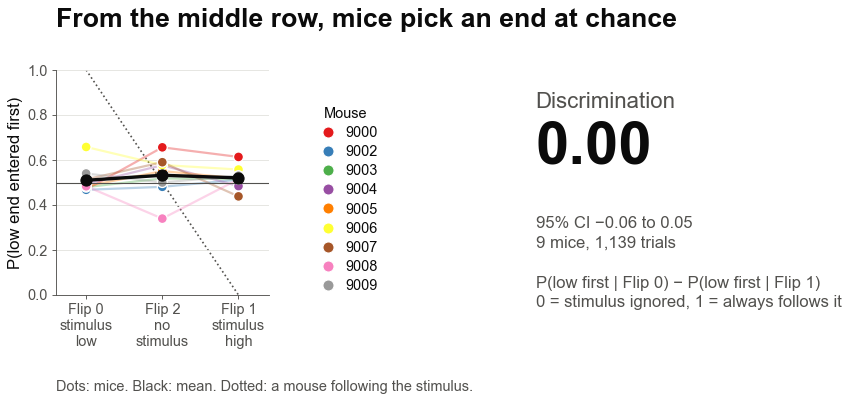

In [4]:
order = [0, 2, 1]
pm = mid.groupby(['mouse', 'flip']).low_first.mean().unstack()[order]

fig, ax = plt.subplots(figsize=FIG, gridspec_kw=padded(top=0.86, bottom=0.21, left=0.08, right=0.44))
for m in pm.index:
    ax.plot(range(3), pm.loc[m], color=MOUSE_COLOR[m], alpha=0.35, lw=2, zorder=1)
for i, flip in enumerate(order):
    ax.scatter(np.full(len(pm), i), pm[flip], s=80, color=[MOUSE_COLOR[m] for m in pm.index], edgecolor=PAPER, lw=1.2, zorder=2)
ax.plot(range(3), pm.mean(), color=INK, lw=3, marker='o', ms=10, zorder=3)
ax.plot(range(3), [1, 0.5, 0], color=MUTED, lw=1.5, ls=':', zorder=0)
ax.axhline(0.5, color=MUTED, lw=1)
ax.set(xticks=range(3), xlim=(-0.4, 2.4), ylim=(0, 1), ylabel='P(low end entered first)')
ax.set_xticklabels([f'Flip {f}\n' + FLIP_CUE[f].replace(' ', '\n') for f in order])
tidy(ax)
mouse_legend(fig, 0.33)
num = lambda v: f'{round(v, 2) + 0:.2f}'.replace('-', '−')    # + 0 turns -0.00 into 0.00
d = direction
fig.text(0.55, 0.72, 'Discrimination', fontsize=20, color=MUTED, ha='left', va='bottom')
fig.text(0.55, 0.7, num(d.effect), fontsize=54, fontweight='bold', color=INK, ha='left', va='top')
fig.text(0.55, 0.46, f'95% CI {num(d.ci_lo)} to {num(d.ci_hi)}\n{len(pm)} mice, {int(d.n_trials):,} trials\n\n'
                    'P(low first | Flip 0) − P(low first | Flip 1)\n0 = stimulus ignored, 1 = always follows it',
         fontsize=15, color=MUTED, ha='left', va='top', linespacing=1.4)
finish(fig, 'From the middle row, mice pick an end at chance', '02_direction',
       key='Dots: mice. Black: mean. Dotted: a mouse following the stimulus.')

## 3. Stimulus vs matched no-stimulus trials

Each stimulus trial is compared with no-stimulus trials from the same mouse, with the target in the same cell and the mouse starting in the same zone, so both pose the same search problem. The search is split at the first moment the mouse enters the target's end: the **approach** is everything before, the **local search** everything after.

- Path lengths are compared as log2 ratios (computed on path + 50 px) and shown as % change in length: 2^effect − 1. The mean across mice is taken on the log scale, so the diamond is the typical (geometric-mean) change.
- Probabilities are shown as the difference in percentage points.
- p is a permutation test: the stimulus label is shuffled within the matched groups 5,000 times.

In [5]:
MATCH = ['target_cell', 'start_zone']
METRICS = {   # slide title: (column, which trials, unit)
    'Whole search\npath':    ('log2_path_px',       ['same end', 'opposite end', 'from middle'], '%'),
    'Approach\npath':        ('log2_reach_path_px', ['opposite end', 'from middle'],             '%'),
    'P(wrong end\nfirst)':   ('wrong_end_first',    ['from middle'],                             'pts'),
    'Local search\npath':    ('log2_local_path_px', ['same end', 'opposite end', 'from middle'], '%'),
    'P(left the\ncorrect end)': ('left_after_reach', ['same end', 'opposite end', 'from middle'], 'pts'),
}
UNIT = {'%': lambda v: (2 ** np.asarray(v, float) - 1) * 100,   # log2 ratio -> % change in length
        'pts': lambda v: np.asarray(v, float) * 100}            # difference in probability -> percentage points
UNIT_LABEL = {'%': '% change in length', 'pts': 'Percentage points'}

cost = t[(t.geometry != 'target in middle') & (t.search_s <= cfg.MAX_SEARCH_S)]
rows = {}
for name, (col, geoms, unit) in METRICS.items():
    d = cost[cost.geometry.isin(geoms)]
    r = summarize(d, col, 'cue', MATCH)
    rows[name.replace('\n', ' ')] = {'no-stimulus mean': d.loc[~d.cue, col].mean(), **r,
                                     'slide value': float(UNIT[unit](r['mouse_mean'])),
                                     'slide CI': tuple(np.round(UNIT[unit]([r['ci_lo'], r['ci_hi']]), 1))}
matched = pd.DataFrame(rows).T
matched

,no-stimulus mean,effect,p_perm,mouse_mean,ci_lo,ci_hi,mice_same_sign,n_trials,slide value,slide CI
Whole search path,11.455,-0.012,0.754,-0.008,-0.096,0.08,3/9,11532,-0.555,"(-6.4, 5.7)"
Approach path,10.331,0.036,0.334,0.03,-0.035,0.094,5/9,6532,2.069,"(-2.4, 6.8)"
P(wrong end first),0.488,0.022,0.459,0.02,-0.065,0.105,5/9,1586,2.013,"(-6.5, 10.5)"
Local search path,10.712,-0.029,0.519,-0.025,-0.126,0.077,5/9,11532,-1.696,"(-8.4, 5.5)"
P(left the correct end),0.414,0.003,0.726,0.005,-0.02,0.03,6/9,11532,0.53,"(-2.0, 3.0)"


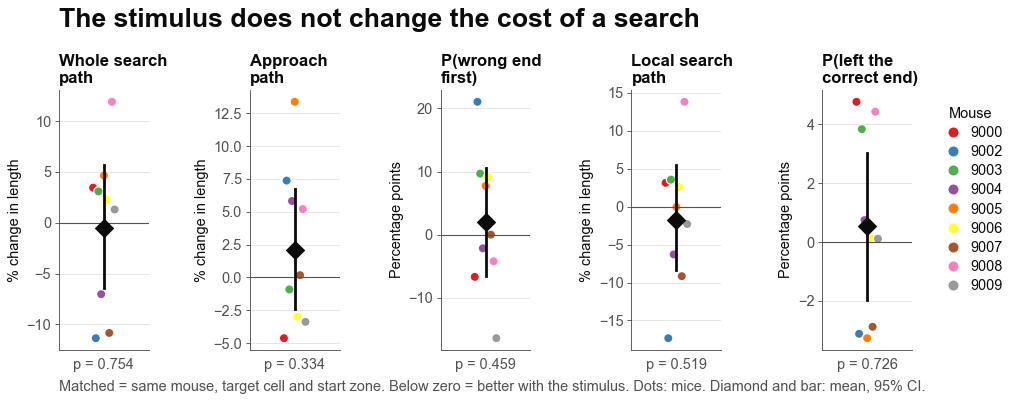

In [6]:
fig, axes = plt.subplots(1, len(METRICS), figsize=FIG, gridspec_kw={'wspace': 0.9 * PAD,
                         **padded(top=0.82, bottom=0.1, left=0.07, right=0.91)})
for ax, (name, (col, geoms, unit)) in zip(axes, METRICS.items()):
    to = UNIT[unit]
    pm = per_mouse(cost[cost.geometry.isin(geoms)], col, 'cue', MATCH).dropna()
    ax.scatter([MOUSE_X[m] for m in pm.index], to(pm), s=70, color=[MOUSE_COLOR[m] for m in pm.index],
               edgecolor=PAPER, lw=1.2, zorder=2)
    r = matched.loc[name.replace('\n', ' ')]
    ax.plot([0, 0], to([r.ci_lo, r.ci_hi]), color=INK, lw=2.5, zorder=3)
    ax.scatter([0], [to(r.mouse_mean)], s=130, color=INK, marker='D', zorder=4)
    ax.axhline(0, color=MUTED, lw=1)
    ax.set(xticks=[], xlim=(-0.5, 0.5))
    ax.set_ylabel(UNIT_LABEL[unit], fontsize=13)
    ax.set_title(name, fontsize=15)
    ax.text(0.5, -0.03, f'p = {r.p_perm:.3f}', transform=ax.transAxes, ha='center', va='top', fontsize=13,
            color=INK if r.p_perm < 0.01 else MUTED)
    tidy(ax)
mouse_legend(fig, 0.9)
finish(fig, 'The stimulus does not change the cost of a search', '03_matched_cost',
       key='Matched = same mouse, target cell and start zone. Below zero = better with the stimulus. '
           'Dots: mice. Diamond and bar: mean, 95% CI.')

### One matched pair

An example of what a single comparison above looks like: a stimulus trial and a no-stimulus trial from the same session, with the same target cell and the same start zone. Chosen from pairs whose SLEAP nose track is clean (no gaps or jumps) and ends at the target cell, with a length difference close to the typical one. The arena is turned on its side to match slide 1 (low end on the left; a rotation of the video, not a mirror image). The path drawn is the SLEAP nose; the lengths are the task's tracked point, as in the comparison.

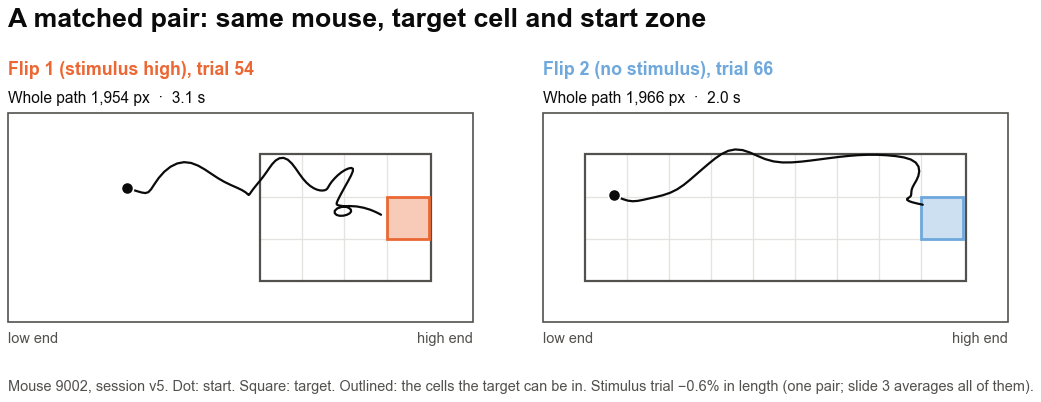

In [7]:
from scipy.ndimage import gaussian_filter1d
from src.trials import USECOLS, discover_sessions, cell_rect

MOUSE, SESSION, CUE_TRIAL, PLAIN_TRIAL = '9002', 'v5', 54, 66
path = next(s['path'] for s in discover_sessions('vision') if (s['mouse'], s['session']) == (MOUSE, SESSION))
ev = pd.read_csv(path, usecols=USECOLS + ['nose_x', 'nose_y'])
pair = t[(t.mouse == MOUSE) & (t.session == SESSION)].set_index('trial').loc[[CUE_TRIAL, PLAIN_TRIAL]]
PAIR_COLOR = {**FLIP_COLOR, 2: '#6fa8dc'}          # this slide only: no-stimulus in a lighter blue
TARGET_ROWS = {0: range(0, 4), 1: range(5, cfg.INNER_ROWS), 2: range(0, cfg.INNER_ROWS)}   # inner rows each flip's target can be in
# cell edges as flip_state_grids.ipynb draws them: the last one runs to the edge of the target grid
ROW_EDGES = np.r_[np.arange(1, cfg.GRID_ROWS - 1) * cfg.CELL_H, cfg.FRAME_H - cfg.CELL_H]
COL_EDGES = np.r_[np.arange(1, cfg.GRID_COLS - 1) * cfg.CELL_W, cfg.FRAME_W - cfg.CELL_W]

fig, axes = plt.subplots(1, 2, figsize=FIG, gridspec_kw={'wspace': 0.12 * PAD, **padded(top=0.8, bottom=0.13, left=0.03, right=0.98)})
for ax, (trial, r) in zip(axes, pair.iterrows()):
    d = ev[ev.trial_number == trial]
    d = d.iloc[:int(np.flatnonzero(d.target_cell.isna().to_numpy())[0]) + 1]      # trial start to target found
    x, y = (gaussian_filter1d(d[c].to_numpy(float), cfg.SMOOTH_SIGMA) for c in ('nose_x', 'nose_y'))
    # on its side: video y runs left to right (low end left), video x bottom to top - a rotation, not a mirror
    vx0, vy0, vx1, vy1 = cell_rect(int(r.target_cell))
    for style in ({'color': PAIR_COLOR[r.flip], 'alpha': 0.35, 'lw': 0}, {'fill': False, 'edgecolor': PAIR_COLOR[r.flip], 'lw': 2.5}):
        ax.add_patch(plt.Rectangle((vy0, vx0), vy1 - vy0, vx1 - vx0, **style))
    # only the cells this flip state's target can be in: faint cell lines, a bold edge around them
    rows = TARGET_ROWS[r.flip]
    gx0, gx1, gy0, gy1 = ROW_EDGES[rows.start], ROW_EDGES[rows.stop], COL_EDGES[0], COL_EDGES[-1]
    for xx in ROW_EDGES[rows.start + 1:rows.stop]:
        ax.plot([xx] * 2, [gy0, gy1], color=GRID, lw=1.2, zorder=0)
    for yy in COL_EDGES[1:-1]:
        ax.plot([gx0, gx1], [yy] * 2, color=GRID, lw=1.2, zorder=0)
    ax.add_patch(plt.Rectangle((gx0, gy0), gx1 - gx0, gy1 - gy0, fill=False, edgecolor=MUTED, lw=2, zorder=0))
    ax.add_patch(plt.Rectangle((0, 0), cfg.FRAME_H, cfg.FRAME_W, fill=False, edgecolor=MUTED, lw=1.5, clip_on=False))   # arena (camera frame)
    ax.plot(y, x, color=INK, lw=2, solid_capstyle='round')
    ax.plot(y[0], x[0], 'o', color=INK, ms=11, mec=PAPER, mew=1.5)
    ax.set(xlim=(0, cfg.FRAME_H), ylim=(0, cfg.FRAME_W), aspect='equal', xticks=[], yticks=[])
    for side in ax.spines.values():
        side.set_visible(False)
    for xx, label, ha in ((0, 'low end', 'left'), (cfg.FRAME_H, 'high end', 'right')):
        ax.text(xx, -40, label, ha=ha, va='top', fontsize=13, color=MUTED)
    ax.set_title(f'Flip {r.flip} ({FLIP_CUE[r.flip]}), trial {trial}', fontsize=16, color=PAIR_COLOR[r.flip], pad=34)
    ax.text(0, cfg.FRAME_W + 30, f'Whole path {r.path_px:,.0f} px  ·  {r.search_s:.1f} s', ha='left', va='bottom',
            fontsize=14, color=INK)
change = (2 ** (np.log2(pair.path_px.iloc[0] + 50) - np.log2(pair.path_px.iloc[1] + 50)) - 1) * 100
finish(fig, 'A matched pair: same mouse, target cell and start zone', '03b_matched_example',
       key=f'Mouse {MOUSE}, session {SESSION}. Dot: start. Square: target. Outlined: the cells the target can be in. Stimulus trial {change:+.1f}% '
           'in length (one pair; slide 3 averages all of them).'.replace('-', '−'))

## 4. Across sessions

Both measures by session number (1st to 10th), pooling mice. Learning would push discrimination toward 1 and the persistence effect below zero.

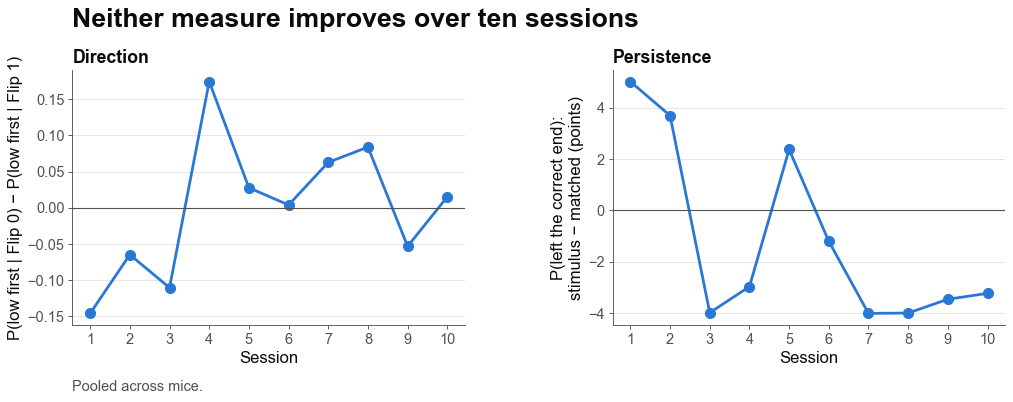

In [8]:
def by_session(d, y, label, keys, min_trials):
    out = d.groupby('session_num')[[y, label] + keys].apply(
        lambda g: pd.Series({'effect': stratified_diff(g, y, label, keys), 'n': len(g)}))
    return out[out.n >= min_trials].effect

disc = by_session(mid[mid.cue], 'low_first', 'is_flip0', ['mouse'], 30)
pers = by_session(cost, 'left_after_reach', 'cue', ['mouse', 'target_zone', 'start_zone'], 150) * 100

fig, axes = plt.subplots(1, 2, figsize=FIG, gridspec_kw={'wspace': 0.3 * PAD, **padded(top=0.86, bottom=0.15, left=0.08, right=0.98)})
for ax, s, title, ylabel in ((axes[0], disc, 'Direction', 'P(low first | Flip 0) − P(low first | Flip 1)'),
                             (axes[1], pers, 'Persistence', 'P(left the correct end):\nstimulus − matched (points)')):
    ax.plot(s.index, s.values, color=LINE, lw=2.5, marker='o', ms=9)
    ax.axhline(0, color=MUTED, lw=1)
    ax.set(xticks=range(1, 11), xlabel='Session', ylabel=ylabel)
    ax.set_title(title, fontsize=16)
    tidy(ax)
finish(fig, 'Neither measure improves over ten sessions', '04_across_sessions', key='Pooled across mice.')